# Experiment 5: Solving the 8-Queens Problem Using Backtracking

### Application: Collision-free placement of components on a grid.

Question

An automated placement system must position eight components on an 8 × 8 grid such that no two components interfere with one another. Model this as the 8-Queens problem, where each queen represents a component and can attack another queen along the same row, column, or diagonal.
Develop a Python program using the backtracking algorithm to find a valid arrangement of eight queens on the chessboard.

The program must:

1.	Represent the chessboard as an 8 × 8 grid and track the positions of the queens.
2.	Place one queen at a time while ensuring that no two queens share the same row, column, or diagonal.
3.	Use recursive backtracking to undo an invalid placement and explore alternative positions.
4.	Display the final chessboard arrangement and the positions of all eight queens.
5.	Report the number of placement attempts and explain how constraint checking and backtracking help find a valid solution.


In [ ]:

N = 8
board = [-1] * N  # board[row] = column
placement_attempts = 0
trace = []

def is_safe(row, col):
    for prev_row in range(row):
        prev_col = board[prev_row]

        # Same column or same diagonal
        if prev_col == col:
            return False

        if abs(prev_col - col) == abs(prev_row - row):
            return False

    return True

def solve(row):
    global placement_attempts

    if row == N:
        return True

    for col in range(N):
        placement_attempts += 1

        if is_safe(row, col):
            board[row] = col
            trace.append(f"Place Q{row + 1} at row {row + 1}, column {col + 1}")

            if solve(row + 1):
                return True

            trace.append(f"Backtrack from row {row + 1}, column {col + 1}")
            board[row] = -1

    return False

print("8-Queens Problem: Backtracking\n")

if solve(0):
    print("--- Execution Trace ---")
    for event in trace:
        print(event)

    print("\n--- Final Chessboard ---")
    for row in range(N):
        print(" ".join("Q" if board[row] == col else "."
                       for col in range(N)))

    print("\n--- Final Result ---")
    print("Solution found: Yes")
    print("Queen positions (row, column):")
    for row, col in enumerate(board):
        print(f"Q{row + 1}: ({row + 1}, {col + 1})")

    print("Placement attempts:", placement_attempts)
    print("Queens placed:", sum(col != -1 for col in board))
else:
    print("No solution found.")


8-Queens Problem: Backtracking

--- Execution Trace ---
Place Q1 at row 1, column 1
Place Q2 at row 2, column 3
Place Q3 at row 3, column 5
Place Q4 at row 4, column 2
Place Q5 at row 5, column 4
Backtrack from row 5, column 4
Place Q5 at row 5, column 8
Backtrack from row 5, column 8
Backtrack from row 4, column 2
Place Q4 at row 4, column 7
Place Q5 at row 5, column 2
Place Q6 at row 6, column 4
Place Q7 at row 7, column 6
Backtrack from row 7, column 6
Backtrack from row 6, column 4
Backtrack from row 5, column 2
Place Q5 at row 5, column 4
Backtrack from row 5, column 4
Backtrack from row 4, column 7
Place Q4 at row 4, column 8
Place Q5 at row 5, column 2
Place Q6 at row 6, column 4
Place Q7 at row 7, column 6
Backtrack from row 7, column 6
Backtrack from row 6, column 4
Backtrack from row 5, column 2
Place Q5 at row 5, column 4
Backtrack from row 5, column 4
Backtrack from row 4, column 8
Backtrack from row 3, column 5
Place Q3 at row 3, column 6
Place Q4 at row 4, column 2
Place 

# Experiment 6: Solving the Map Colouring Problem Using CSP

### Application: Frequency allocation for neighbouring cellular network regions.

Question

A telecommunications network is divided into interconnected regions. To reduce interference, neighbouring regions must be assigned different frequency bands. Model the network as a Constraint Satisfaction Problem (CSP), where each region is a variable, the available frequency bands form its domain, and neighbouring regions must receive different assignments.
Develop a Python program to solve the map-colouring problem using CSP techniques.

The program must:

1.	Represent each region as a variable and define its available colours as a domain.
2.	Specify adjacency constraints requiring neighbouring regions to have different colours.
3.	Use backtracking search to find a valid colour assignment.
4.	Display the final map-colouring assignment and verify that all adjacency constraints are satisfied.
5.	Report the number of assignments attempted and explain how CSP variables, domains, and constraints guide the search.


In [ ]:

# Experiment 9: Map Colouring Using CSP
# Application: Frequency allocation in a cellular network

regions = {
    "A": ["B", "C"],
    "B": ["A", "C", "D"],
    "C": ["A", "B", "D", "E"],
    "D": ["B", "C", "E", "F"],
    "E": ["C", "D", "F"],
    "F": ["D", "E"]
}

colours = ["Red", "Green", "Blue"]
assignment = {}
attempts = 0
trace = []

def is_valid(region, colour):
    for neighbour in regions[region]:
        if assignment.get(neighbour) == colour:
            return False
    return True

def solve(region_index):
    global attempts

    region_list = list(regions.keys())

    if region_index == len(region_list):
        return True

    region = region_list[region_index]

    for colour in colours:
        attempts += 1
        trace.append(f"Try {region} = {colour}")

        if is_valid(region, colour):
            assignment[region] = colour
            trace.append(f"  Assigned {region} = {colour}")

            if solve(region_index + 1):
                return True

            trace.append(f"  Backtrack from {region} = {colour}")
            del assignment[region]
        else:
            trace.append(f"  Rejected: neighbouring region has {colour}")

    return False

print("Map Colouring Problem Using CSP\n")

if solve(0):
    print("--- Execution Trace ---")
    for step in trace:
        print(step)

    print("\n--- Final Colour Assignment ---")
    for region, colour in assignment.items():
        print(f"Region {region}: {colour}")

    print("\n--- Constraint Verification ---")
    valid = True

    for region, neighbours in regions.items():
        for neighbour in neighbours:
            if assignment[region] == assignment[neighbour]:
                print(f"Conflict: {region} and {neighbour}")
                valid = False

    print("All adjacency constraints satisfied:", valid)
    print("Assignments attempted:", attempts)
else:
    print("No valid colour assignment found.")


Map Colouring Problem Using CSP

--- Execution Trace ---
Try A = Red
  Assigned A = Red
Try B = Red
  Rejected: neighbouring region has Red
Try B = Green
  Assigned B = Green
Try C = Red
  Rejected: neighbouring region has Red
Try C = Green
  Rejected: neighbouring region has Green
Try C = Blue
  Assigned C = Blue
Try D = Red
  Assigned D = Red
Try E = Red
  Rejected: neighbouring region has Red
Try E = Green
  Assigned E = Green
Try F = Red
  Rejected: neighbouring region has Red
Try F = Green
  Rejected: neighbouring region has Green
Try F = Blue
  Assigned F = Blue

--- Final Colour Assignment ---
Region A: Red
Region B: Green
Region C: Blue
Region D: Red
Region E: Green
Region F: Blue

--- Constraint Verification ---
All adjacency constraints satisfied: True
Assignments attempted: 12


# Experiment 7 - Implementing the Minimax Algorithm

### Application: Decision-making in a two-player strategy game.

Question

A game-playing AI must select its best move in a two-player game where one player tries to maximize the score while the opponent tries to minimize it.
Develop a Python program to implement the Minimax algorithm for a game represented as a binary game tree.

The program must:

1.	Represent the game tree with terminal utility values.
2.	Treat the AI as the maximizing player and the opponent as the minimizing player.
3.	Recursively evaluate the game tree using the Minimax algorithm.
4.	Display the evaluated values and the best move selected by the AI.
5.	Explain how the algorithm assumes that both players choose optimal moves.

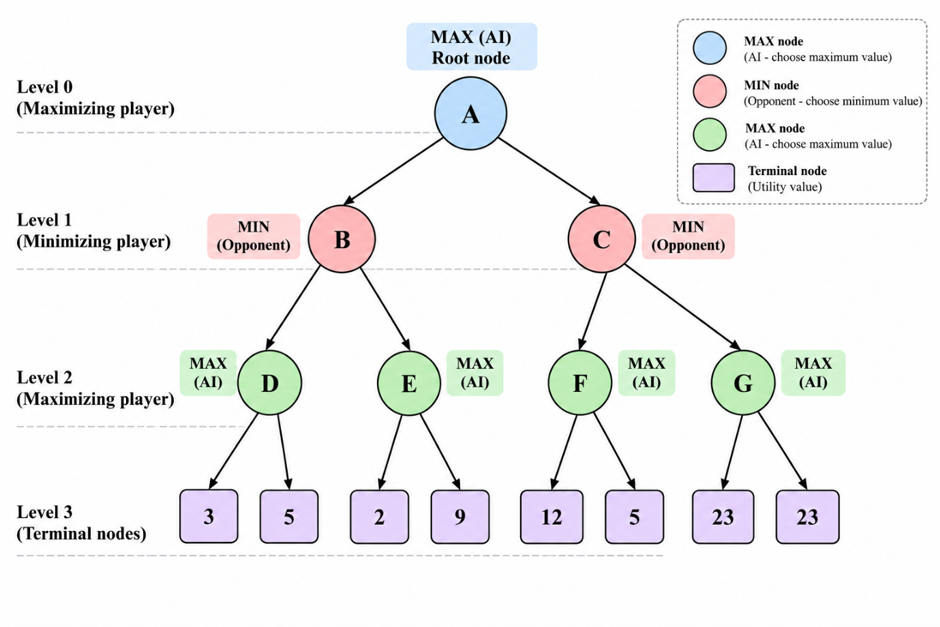


In [ ]:

# Experiment 11: Minimax Algorithm
# Application: Decision-making in a two-player strategy game

game_tree = {
    "A": ["B", "C"],
    "B": ["D", "E"],
    "C": ["F", "G"],
    "D": [3, 5],
    "E": [2, 9],
    "F": [12, 5],
    "G": [23, 23]
}

evaluated_values = {}

def minimax(node, is_maximizing):
    # Terminal node: return its utility value
    if isinstance(node, int):
        return node

    children = game_tree[node]
    values = []

    for child in children:
        value = minimax(child, not is_maximizing)
        values.append(value)

    if is_maximizing:
        best_value = max(values)
    else:
        best_value = min(values)

    evaluated_values[node] = best_value
    print(f"Node {node} ({'MAX' if is_maximizing else 'MIN'}): "
          f"Values = {values}, Selected = {best_value}")

    return best_value

print("Minimax Algorithm\n")
best_value = minimax("A", True)


print("\n--- Final Result ---")
print("Root node value:", best_value)

best_move = max(
    game_tree["A"],
    key=lambda child: evaluated_values[child]
)

print("Best move for AI: Node", best_move)
print("Expected utility:", evaluated_values[best_move])


Minimax Algorithm

Node D (MAX): Values = [3, 5], Selected = 5
Node E (MAX): Values = [2, 9], Selected = 9
Node B (MIN): Values = [5, 9], Selected = 5
Node F (MAX): Values = [12, 5], Selected = 12
Node G (MAX): Values = [23, 23], Selected = 23
Node C (MIN): Values = [12, 23], Selected = 12
Node A (MAX): Values = [5, 12], Selected = 12

--- Final Result ---
Root node value: 12
Best move for AI: Node C
Expected utility: 12


# Experiment 12 - Implementing Alpha-Beta Pruning

### Application: Optimizing decision-making in a two-player strategy game.

Question

A chess-playing AI evaluates possible moves by exploring a game tree. Since evaluating every possible move is computationally expensive, the AI uses Alpha-Beta Pruning to eliminate branches that cannot influence the final decision.
Develop a Python program to implement the Alpha-Beta Pruning algorithm for a chess-inspired game tree with multiple possible moves and terminal utility values.

The program must:

1.	Represent the game tree with multiple candidate moves and terminal utility values.
2.	Implement Alpha-Beta Pruning using alpha and beta bounds.
3.	Identify and skip branches that cannot affect the final decision.
4.	Display the selected move, its utility value, the number of nodes evaluated, and the number of branches pruned.
5.	Explain how Alpha-Beta Pruning reduces the search effort while preserving the optimal decision.

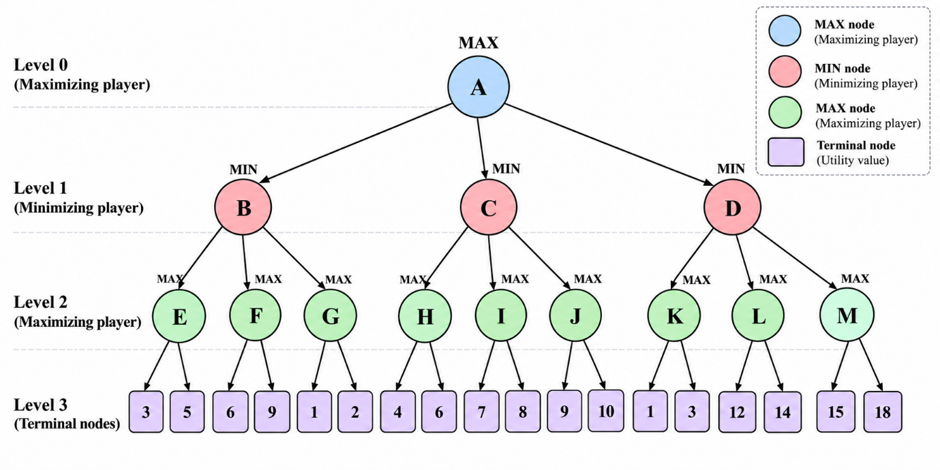


In [ ]:

# Experiment 12: Alpha-Beta Pruning
# Application: Chess-inspired AI move selection

game_tree = {
    "A": ["B", "C", "D"],
    "B": ["E", "F", "G"],
    "C": ["H", "I", "J"],
    "D": ["K", "L", "M"],
    "E": [3, 5],
    "F": [6, 9],
    "G": [1, 2],
    "H": [4, 6],
    "I": [7, 8],
    "J": [9, 10],
    "K": [1, 3],
    "L": [12, 14],
    "M": [15, 18]
}

nodes_evaluated = 0
branches_pruned = 0
evaluated_values = {}

def alphabeta(node, alpha, beta, is_maximizing):
    global nodes_evaluated, branches_pruned

    nodes_evaluated += 1

    # Return the utility of a terminal node
    if isinstance(node, int):
        print(f"Evaluate terminal value: {node}")
        return node

    player = "MAX" if is_maximizing else "MIN"
    print(f"\nVisit {node} ({player})")

    value = float("-inf") if is_maximizing else float("inf")
    children = game_tree[node]

    for index, child in enumerate(children):
        child_value = alphabeta(
            child, alpha, beta, not is_maximizing
        )

        if is_maximizing:
            value = max(value, child_value)
            alpha = max(alpha, value)
        else:
            value = min(value, child_value)
            beta = min(beta, value)

        print(
            f"Node {node}: value={value}, "
            f"alpha={alpha}, beta={beta}"
        )

        # Prune remaining branches when they cannot affect the result
        if alpha >= beta:
            remaining = len(children) - index - 1
            branches_pruned += remaining

            if remaining > 0:
                print(
                    f"Prune {remaining} remaining branch(es) "
                    f"at node {node}"
                )
            break

    evaluated_values[node] = value
    return value


print("Alpha-Beta Pruning Algorithm\n")

root_value = alphabeta("A", float("-inf"), float("inf"), True)

best_move = max(
    game_tree["A"],
    key=lambda child: evaluated_values[child]
)

print("\n--- Final Result ---")
print("Root node value:", root_value)
print("Best move for AI:", best_move)
print("Expected utility:", evaluated_values[best_move])
print("Nodes evaluated:", nodes_evaluated)
print("Branches pruned:", branches_pruned)


Alpha-Beta Pruning Algorithm


Visit A (MAX)

Visit B (MIN)

Visit E (MAX)
Evaluate terminal value: 3
Node E: value=3, alpha=3, beta=inf
Evaluate terminal value: 5
Node E: value=5, alpha=5, beta=inf
Node B: value=5, alpha=-inf, beta=5

Visit F (MAX)
Evaluate terminal value: 6
Node F: value=6, alpha=6, beta=5
Prune 1 remaining branch(es) at node F
Node B: value=5, alpha=-inf, beta=5

Visit G (MAX)
Evaluate terminal value: 1
Node G: value=1, alpha=1, beta=5
Evaluate terminal value: 2
Node G: value=2, alpha=2, beta=5
Node B: value=2, alpha=-inf, beta=2
Node A: value=2, alpha=2, beta=inf

Visit C (MIN)

Visit H (MAX)
Evaluate terminal value: 4
Node H: value=4, alpha=4, beta=inf
Evaluate terminal value: 6
Node H: value=6, alpha=6, beta=inf
Node C: value=6, alpha=2, beta=6

Visit I (MAX)
Evaluate terminal value: 7
Node I: value=7, alpha=7, beta=6
Prune 1 remaining branch(es) at node I
Node C: value=6, alpha=2, beta=6

Visit J (MAX)
Evaluate terminal value: 9
Node J: value=9, alpha=9, beta=6
